# Experimento 9 — AutoGluon Tabular

Mesmas 14 features e histórico principal dos Exp. 7/8 (M: 2003+, W: 2010+), sem Elo.
Target e previsões continuam margens A − B, com TeamA menor que TeamB.
A Logistic Brier passa a orientar tanto a seleção interna quanto a avaliação externa.
O notebook anterior de H2O/DL foi preservado com seu nome original.

## Configuração

Instale `requirements-autogluon.txt` no ambiente deste kernel antes da execução:
`%pip install -r ../../requirements-autogluon.txt` (caminho relativo à pasta deste notebook).
Não é necessário criar uma nova `.venv`. AutoGluon 1.6.3 suporta Python 3.10–3.13.

In [1]:
from pathlib import Path
import sys
import json
from importlib.metadata import version

import numpy as np
import pandas as pd
from IPython.display import display

pasta_atual = Path.cwd().resolve()
raiz = next((p for p in [pasta_atual, *pasta_atual.parents] if (p / "raw_data").is_dir()), None)
if raiz is None:
    raise FileNotFoundError("Pasta raw_data não encontrada.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.data_processing import carregar_dados, preparar_seeds, organizar_jogos
from src.features import (
    adicionar_seeds, calcular_estatisticas_agregadas, adicionar_estatisticas,
    ESTATISTICAS_DETALHADAS, calcular_estatisticas_detalhadas, adicionar_estatisticas_detalhadas,
)
from src.automl_autogluon import (
    ambiente_autogluon, avaliar_temporadas_autogluon, treinar_automl,
    limpar_execucao, AdaptadorAutoGluon,
)
from src.submission import preparar_confrontos, prever_confrontos, salvar_submission

EXPERIMENTO = "exp9_autogluon"
FEATURES_EXP4 = ["SeedDif", "WinRateDiff", "AvgPointsForDiff", "AvgPointsAgainstDiff", "OppWinRateDiff"]
FEATURES = [*FEATURES_EXP4, *[nome + "Diff" for nome in ESTATISTICAS_DETALHADAS]]
INICIO_DETALHADO = {"M": 2003, "W": 2010}
ANOS_VALIDACAO = list(range(2021, 2026))
TEMPORADA_PREVISAO = 2026
LIMITE_DAYNUM_PREVISAO = 134
CATEGORIAS = {"M": "Masculino", "W": "Feminino"}
SEED = 42
PRESET = "best_quality"
TIME_LIMIT = 300
N_FOLDS_INTERNOS = 5
TOP_N = 3

REFERENCIA_EXP7 = json.loads(r'''{"features": ["SeedDif", "WinRateDiff", "AvgPointsForDiff", "AvgPointsAgainstDiff", "OppWinRateDiff", "FGPercentageDiff", "ThreePointPercentageDiff", "FTPercentageDiff", "AssistsPerGameDiff", "OffensiveReboundsPerGameDiff", "DefensiveReboundsPerGameDiff", "TurnoversPerGameDiff", "StealsPerGameDiff", "BlocksPerGameDiff"], "anos_validacao": [2021, 2022, 2023, 2024, 2025], "inicio_detalhado": {"M": 2003, "W": 2010}, "versoes": {"numpy": "2.2.6", "pandas": "2.3.2", "scikit-learn": "1.7.1", "xgboost": "3.0.5", "optuna": "4.9.0"}, "cenario": "Exp7 disponivel", "medias": {"linear": 0.07235902247317808, "random_forest": 0.07059117078512692, "xgboost": 0.06962912060600238}, "fonte": "notebooks/features_incrementais/exp7_features_detalhadas.ipynb: registro salvo", "sha256_notebook": "ebfa70c730e9b02c745e466e8cacde67a33136e365143c826e5ba5257823bf37"}''')

assert FEATURES == REFERENCIA_EXP7["features"]
assert ANOS_VALIDACAO == REFERENCIA_EXP7["anos_validacao"]
assert INICIO_DETALHADO == REFERENCIA_EXP7["inicio_detalhado"]

REFERENCIA_EXP8 = {
    "media": 0.07192892829650815,
    "fonte": "notebooks/features_incrementais/exp8_h2o_automl.ipynb: registro salvo",
    "metrica_interna": "RMSE",
}
assert len(FEATURES) == 14 and "EloDiff" not in FEATURES
assert not {"Season", "Target", "TeamA", "TeamB"} & set(FEATURES)

## Preparação dos dados

Mesma preparação do Exp. 8, exclusivamente com resultados regulares pré-NCAA.
Em 2026: `DayNum < 134`. A cobertura detalhada incompleta de W em 2010–2012
é mantida como nos Exp. 7/8; nenhuma partida do torneio é descartada silenciosamente.

In [2]:
dados = {
    categoria: carregar_dados(raiz / "raw_data", categoria, incluir_regular=True, incluir_detalhado=True)
    for categoria in CATEGORIAS
}
assert set(dados["M"]["times"]["TeamID"]).isdisjoint(set(dados["W"]["times"]["TeamID"]))
seeds, estatisticas, detalhadas, jogos, limites, coberturas = {}, {}, {}, {}, {}, []
chaves_jogo = ["Season", "DayNum", "WTeamID", "LTeamID"]
for categoria, base in dados.items():
    torneios = base["resultados"].loc[base["resultados"]["Season"] < TEMPORADA_PREVISAO].copy()
    limites[categoria] = torneios.groupby("Season")["DayNum"].min().to_dict()
    limites[categoria][TEMPORADA_PREVISAO] = LIMITE_DAYNUM_PREVISAO
    raw_detalhes = base["temporada_regular_detalhada"]
    assert raw_detalhes["Season"].min() == INICIO_DETALHADO[categoria]
    anos = set(raw_detalhes["Season"]) & set(limites[categoria])
    assert set([*ANOS_VALIDACAO, TEMPORADA_PREVISAO]).issubset(anos)
    regulares = base["temporada_regular"].loc[base["temporada_regular"]["Season"].isin(anos)].copy()
    detalhes = raw_detalhes.loc[raw_detalhes["Season"].isin(anos)].copy()
    ids = set(base["times"]["TeamID"])
    for tabela in [regulares, detalhes]:
        assert (tabela["DayNum"] < tabela["Season"].map(limites[categoria])).all()
        assert tabela.merge(torneios[chaves_jogo], on=chaves_jogo).empty
        assert tabela["WTeamID"].isin(ids).all() and tabela["LTeamID"].isin(ids).all()
    conferidos = detalhes.merge(regulares[chaves_jogo + ["WScore", "LScore"]],
        on=chaves_jogo, how="left", suffixes=("", "Compact"), validate="one_to_one", indicator=True)
    assert conferidos["_merge"].eq("both").all()
    for placar in ["WScore", "LScore"]:
        np.testing.assert_array_equal(conferidos[placar], conferidos[placar + "Compact"])

    cobertura = regulares.groupby("Season").size().rename("JogosCompact").to_frame()
    cobertura["JogosDetalhados"] = detalhes.groupby("Season").size()
    cobertura["SemDetalhes"] = cobertura["JogosCompact"] - cobertura["JogosDetalhados"]
    cobertura["Cobertura"] = cobertura["JogosDetalhados"] / cobertura["JogosCompact"]
    cobertura["UltimoDayNumDetalhado"] = detalhes.groupby("Season")["DayNum"].max()
    cobertura["LimiteExclusivo"] = cobertura.index.map(limites[categoria])
    coberturas.append(cobertura.reset_index().assign(Categoria=categoria))
    seeds[categoria] = preparar_seeds(base["seeds"])
    estatisticas[categoria] = calcular_estatisticas_agregadas(regulares, limites_daynum=limites[categoria])
    detalhadas[categoria] = calcular_estatisticas_detalhadas(detalhes, limites_daynum=limites[categoria])
    historico = torneios.loc[torneios["Season"].isin(anos)]
    tabela = adicionar_seeds(organizar_jogos(historico), seeds[categoria])
    tabela = adicionar_estatisticas(tabela, estatisticas[categoria])
    tabela = adicionar_estatisticas_detalhadas(tabela, detalhadas[categoria])
    assert len(tabela) == len(historico)
    assert (tabela["TeamA"] < tabela["TeamB"]).all()
    assert tabela["Target"].equals(tabela["ScoreA"] - tabela["ScoreB"])
    assert tabela["SeedDif"].equals(tabela["SeedA"] - tabela["SeedB"])
    assert np.isfinite(tabela[FEATURES].to_numpy()).all()
    for stats, nomes in [(estatisticas[categoria], ["WinRate", "AvgPointsFor", "AvgPointsAgainst", "OppWinRate"]),
                          (detalhadas[categoria], ESTATISTICAS_DETALHADAS)]:
        lookup = stats.set_index(["Season", "TeamID"])
        for nome in nomes:
            a = lookup[nome].reindex(pd.MultiIndex.from_frame(tabela[["Season", "TeamA"]])).to_numpy()
            b = lookup[nome].reindex(pd.MultiIndex.from_frame(tabela[["Season", "TeamB"]])).to_numpy()
            np.testing.assert_allclose(tabela[nome + "Diff"], a - b)
    jogos[categoria] = tabela

cobertura = pd.concat(coberturas, ignore_index=True)
display(cobertura)

divisoes = pd.DataFrame([
    {"Categoria": categoria, "AnoValidacao": ano,
     "PrimeiroAnoTreino": tabela.loc[tabela.Season < ano, "Season"].min(),
     "UltimoAnoTreino": tabela.loc[tabela.Season < ano, "Season"].max(),
     "JogosTreino": int(tabela.Season.lt(ano).sum()), "JogosValidacao": int(tabela.Season.eq(ano).sum())}
    for categoria, tabela in jogos.items() for ano in ANOS_VALIDACAO
])
assert (divisoes.UltimoAnoTreino < divisoes.AnoValidacao).all()
assert divisoes.JogosValidacao.gt(0).all()
assert divisoes.loc[divisoes.AnoValidacao.eq(2021), "UltimoAnoTreino"].eq(2019).all()
for categoria, tabela in jogos.items():
    assert tabela.Season.max() == 2025
    assert tabela.Season.min() == INICIO_DETALHADO[categoria]
    assert np.isfinite(tabela[[*FEATURES, "Target"]].to_numpy()).all()
display(divisoes)

,Season,JogosCompact,JogosDetalhados,SemDetalhes,Cobertura,UltimoDayNumDetalhado,LimiteExclusivo,Categoria
0,2003,4616,4616,0,1.000000,132,134,M
1,2004,4571,4571,0,1.000000,132,134,M
2,2005,4675,4675,0,1.000000,132,134,M
3,2006,4757,4757,0,1.000000,132,134,M
4,2007,5043,5043,0,1.000000,132,134,M
5,2008,5163,5163,0,1.000000,132,134,M
6,2009,5249,5249,0,1.000000,132,134,M
7,2010,5263,5263,0,1.000000,132,134,M
8,2011,5246,5246,0,1.000000,132,134,M
9,2012,5253,5253,0,1.000000,132,134,M


,Categoria,AnoValidacao,PrimeiroAnoTreino,UltimoAnoTreino,JogosTreino,JogosValidacao
0,M,2021,2003,2019,1115,66
1,M,2022,2003,2021,1181,67
2,M,2023,2003,2022,1248,67
3,M,2024,2003,2023,1315,67
4,M,2025,2003,2024,1382,67
5,W,2021,2010,2019,630,63
6,W,2022,2010,2021,693,67
7,W,2023,2010,2022,760,67
8,W,2024,2010,2023,827,67
9,W,2025,2010,2024,894,67


## Logistic Brier customizada

O scorer importável reutiliza `src.metrics.logistic_brier`, que calcula a diferença
quadrática entre `sigmoid(pred/7)` e `sigmoid(target/7)`. A regressão recebe margens.
AutoGluon maximiza `score_val = -LogisticBrier`; nas tabelas, `LogisticBrier` é positivo
e menor é melhor. O atributo `greater_is_better_internal` descreve a função original.

In [3]:
from src.metrics import logistic_brier
from src.metrics_autogluon import logistic_brier_scorer

y_exemplo = np.array([-7., 0., 14.])
p_exemplo = np.array([-4., 2., 8.])
assert logistic_brier_scorer.optimum == 0
assert not logistic_brier_scorer.greater_is_better_internal
assert -logistic_brier_scorer(y_exemplo, p_exemplo) == logistic_brier(y_exemplo, p_exemplo)

## AutoGluon

300 segundos por busca, iguais nas dez validações e nos dois treinos finais.
O tempo total pode ultrapassar 60 minutos com preparação, ensembles e exportação.
Usamos `best_quality`, cinco folds por Season, uma repetição e um nível de stacking.
DyStack fica desativado para evitar buscas auxiliares neste orçamento; weighted ensembles
continuam habilitados. Nenhuma família é filtrada e não há seleção de features.

`validation_structure={"group_on": "Season"}` separa temporadas inteiras; Season é
removida das entradas preditivas via `ignored_columns`. A CV interna é agrupada,
não expansiva. Apenas a avaliação externa exige treino estritamente anterior ao ano.
Seed fixa não garante resultados idênticos com limite de tempo e backends diferentes.

[API do fit](https://auto.gluon.ai/stable/api/autogluon.tabular.TabularPredictor.fit.html)
e [pacote 1.6.3](https://pypi.org/project/autogluon.tabular/1.6.3/).

In [4]:
CONFIG_AUTOML = {
    "seed": SEED, "preset": PRESET, "time_limit": TIME_LIMIT, "n_folds": N_FOLDS_INTERNOS,
}
CONFIG_INTERNA = {
    "eval_metric": "logistic_brier", "validation_structure": {"group_on": "Season"},
    "ignored_columns": ["Season"], "num_bag_sets": 1, "num_stack_levels": 1,
    "dynamic_stacking": False, "use_bag_holdout": False, "feature_prune_kwargs": None,
}
VERSOES = ambiente_autogluon()
display(pd.Series(VERSOES, name="Versão instalada").to_frame())
display(CONFIG_AUTOML)

,Versão instalada
autogluon.tabular,1.6.3
numpy,2.2.6
pandas,2.3.2
scipy,1.15.3
scikit-learn,1.7.1
lightgbm,4.6.0
catboost,1.2.8
xgboost,3.0.5
xgboost-cpu,3.3.0
torch,2.13.0


{'seed': 42, 'preset': 'best_quality', 'time_limit': 300, 'n_folds': 5}

## Validação temporal 2021–2025

Uma busca independente por categoria/ano, sempre com `Season < ano`.
O ano externo nunca é enviado como `tuning_data`. Após prever o ano externo,
os arquivos daquela busca são apagados; tabelas e previsões ficam em memória.

In [5]:
avaliacao = avaliar_temporadas_autogluon(
    jogos, ANOS_VALIDACAO, features=FEATURES, **CONFIG_AUTOML,
)
scores_anuais = avaliacao["resultados"]
leaders = avaliacao["leaders"]
assert len(leaders) == 2 * len(ANOS_VALIDACAO)
assert (scores_anuais.UltimoAnoTreino < scores_anuais.Season).all()
assert avaliacao["folds"].Season.lt(avaliacao["folds"].AnoValidacao).all()
assert avaliacao["folds"].groupby(["Categoria", "AnoValidacao", "Season"]).FoldInterno.nunique().eq(1).all()
assert avaliacao["folds"].groupby(["Categoria", "AnoValidacao"]).FoldInterno.nunique().eq(N_FOLDS_INTERNOS).all()

Will use sequential fold fitting strategy because import of ray failed. Reason: ray is required to train folds in parallel for TabularPredictor or HPO for MultiModalPredictor. A quick tip is to install via `pip install "ray>=2.43.0,<2.59.0"`
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_

M/2021: WeightedEnsemble_L3 — Logistic Brier 0.088242


Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!


W/2021: WeightedEnsemble_L3 — Logistic Brier 0.070962


Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!


...

W/2024: WeightedEnsemble_L3 — Logistic Brier 0.041776


Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!


M/2025: WeightedEnsemble_L3 — Logistic Brier 0.056416


Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!


W/2025: WeightedEnsemble_L2 — Logistic Brier 0.047357


## Resultados por temporada

O score combinado reúne todas as previsões M/W do ano. O resultado do experimento
é a média simples desses cinco scores combinados, sem seleção pelo Kaggle.

Categoria,M,W,Combinado
Season,,,
2021,0.088242,0.070962,0.079803
2022,0.080332,0.074942,0.077637
2023,0.086010,0.069145,0.077577
2024,0.077161,0.041776,0.059468
2025,0.056416,0.047357,0.051886


Média Logistic Brier 2021–2025: 0.06927442


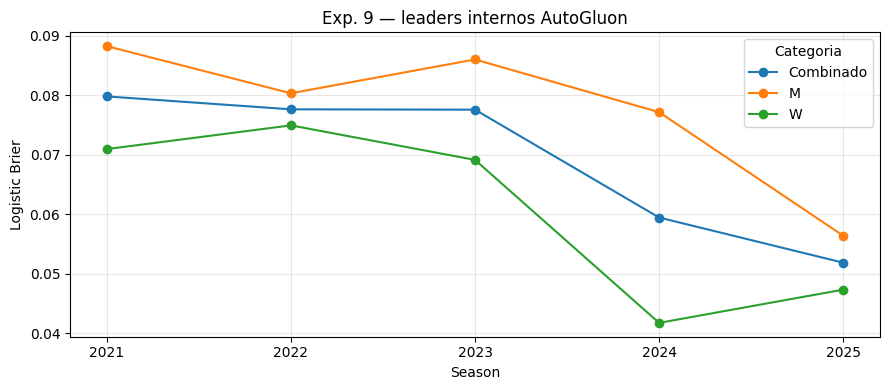

In [6]:
tabela_scores = scores_anuais.pivot(index="Season", columns="Categoria", values="Score")
display(tabela_scores[["M", "W", "Combinado"]])
print(f"Média Logistic Brier 2021–2025: {avaliacao['media']:.8f}")

import matplotlib.pyplot as plt
ax = tabela_scores.plot(marker="o", figsize=(9, 4), ylabel="Logistic Brier",
    title="Exp. 9 — leaders internos AutoGluon", xticks=ANOS_VALIDACAO)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Modelos escolhidos

As famílias abaixo são as efetivamente treinadas. Pacote instalado não garante
treino bem-sucedido; falhas de modelos opcionais são registradas sem interromper
os demais. Se nenhum modelo conseguir treinar, a execução precisa ser corrigida.

In [7]:
display(leaders)
frequencias = leaders.groupby(["Familia", "Categoria"]).size().unstack(fill_value=0)
frequencias["Total"] = frequencias.sum(axis=1)
display(frequencias.sort_values("Total", ascending=False))
familias_treinadas = sorted(set().union(*[set(lb.Familia) for lb in avaliacao["leaderboards"].values()]))
print("Famílias treinadas:", familias_treinadas)
display(avaliacao["leaderboards"][f"M_{ANOS_VALIDACAO[0]}"].head(10))
resumo_leaderboards = pd.concat([
    lb.head(3).assign(Execucao=nome) for nome, lb in avaliacao["leaderboards"].items()
], ignore_index=True)
display(resumo_leaderboards)
falhas_historicas = pd.concat([
    tabela.assign(Execucao=nome) for nome, tabela in avaliacao["falhas"].items()
], ignore_index=True)
display(falhas_historicas.drop_duplicates().head(20))

,Season,Categoria,Score,JogosTreino,JogosValidacao,UltimoAnoTreino,model,Familia,score_val,LogisticBrierInterno
0,2021,M,0.088242,1115,66,2019,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.063649,0.063649
1,2021,W,0.070962,630,63,2019,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.053549,0.053549
2,2022,M,0.080332,1181,67,2021,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.063812,0.063812
3,2022,W,0.074942,693,67,2021,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.055284,0.055284
4,2023,M,0.086010,1248,67,2022,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.065236,0.065236
5,2023,W,0.069145,760,67,2022,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.055924,0.055924
6,2024,M,0.077161,1315,67,2023,WeightedEnsemble_L2,GreedyWeightedEnsembleModel,-0.066781,0.066781
7,2024,W,0.041776,827,67,2023,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.057913,0.057913
8,2025,M,0.056416,1382,67,2024,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.066842,0.066842
9,2025,W,0.047357,894,67,2024,WeightedEnsemble_L2,GreedyWeightedEnsembleModel,-0.057495,0.057495


Categoria,M,W,Total
Familia,,,
GreedyWeightedEnsembleModel,5,5,10


Famílias treinadas: ['CatBoostModel', 'GreedyWeightedEnsembleModel', 'LGBModel', 'NNFastAiTabularModel', 'RFModel', 'TabularNeuralNetTorchModel', 'XGBoostModel', 'XTModel']


,model,Familia,score_val,LogisticBrier,fit_time,pred_time_val,stack_level
0,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.063649,0.063649,92.134358,0.997850,3
1,WeightedEnsemble_L2,GreedyWeightedEnsembleModel,-0.063924,0.063924,62.533443,0.159870,2
2,NeuralNetTorch_r22_BAG_L1,TabularNeuralNetTorchModel,-0.065047,0.065047,10.842283,0.016002,1
3,LightGBM_r96_BAG_L2,LGBModel,-0.065478,0.065478,82.263376,0.951218,2
4,LightGBMXT_BAG_L2,LGBModel,-0.065756,0.065756,82.772532,0.951696,2
5,LightGBM_r96_BAG_L1,LGBModel,-0.066028,0.066028,1.646521,0.003721,1
6,LightGBM_r188_BAG_L1,LGBModel,-0.066647,0.066647,2.864992,0.003563,1
7,LightGBMXT_BAG_L1,LGBModel,-0.066765,0.066765,1.946295,0.003154,1
8,NeuralNetTorch_r22_BAG_L2,TabularNeuralNetTorchModel,-0.066855,0.066855,87.741181,0.964050,2
9,LightGBM_r130_BAG_L1,LGBModel,-0.066996,0.066996,1.588728,0.003278,1


,model,Familia,score_val,LogisticBrier,fit_time,pred_time_val,stack_level,Execucao
0,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.063649,0.063649,92.134358,0.997850,3,M_2021
1,WeightedEnsemble_L2,GreedyWeightedEnsembleModel,-0.063924,0.063924,62.533443,0.159870,2,M_2021
2,NeuralNetTorch_r22_BAG_L1,TabularNeuralNetTorchModel,-0.065047,0.065047,10.842283,0.016002,1,M_2021
3,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.053549,0.053549,51.990998,0.475339,3,W_2021
4,WeightedEnsemble_L2,GreedyWeightedEnsembleModel,-0.055719,0.055719,28.942155,0.072203,2,W_2021
5,NeuralNetTorch_r79_BAG_L2,TabularNeuralNetTorchModel,-0.056445,0.056445,50.425727,0.470059,2,W_2021
6,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.063812,0.063812,100.723660,1.023147,3,M_2022
7,WeightedEnsemble_L2,GreedyWeightedEnsembleModel,-0.064406,0.064406,48.511248,0.061771,2,M_2022
8,LightGBM_r131_BAG_L2,LGBModel,-0.065825,0.065825,94.462595,0.982041,2,M_2022
9,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,-0.055284,0.055284,52.347964,0.485893,3,W_2022


,model,model_type,exc_type,exc_str,Execucao
0,NeuralNetFastAI_r11_BAG_L1,StackerEnsembleModel,TimeLimitExceeded,,M_2021
1,XGBoost_r194_BAG_L1,StackerEnsembleModel,TimeLimitExceeded,,M_2021
2,LightGBM_r15_BAG_L1,StackerEnsembleModel,TimeLimitExceeded,,W_2021
3,NeuralNetTorch_r158_BAG_L1,StackerEnsembleModel,TimeLimitExceeded,,W_2021
4,XGBoost_r194_BAG_L1,StackerEnsembleModel,TimeLimitExceeded,,M_2022
5,ExtraTrees_r172_BAG_L1,StackerEnsembleModel,TimeLimitExceeded,,M_2022
6,LightGBM_r196_BAG_L1,StackerEnsembleModel,TimeLimitExceeded,,W_2022
7,NeuralNetFastAI_r11_BAG_L1,StackerEnsembleModel,TimeLimitExceeded,,M_2023
8,NeuralNetFastAI_r143_BAG_L1,StackerEnsembleModel,TimeLimitExceeded,,W_2023
9,NeuralNetFastAI_r11_BAG_L1,StackerEnsembleModel,TimeLimitExceeded,,M_2024


## Comparação Exp. 7 × Exp. 8 × Exp. 9

Referências salvas no repositório, com as mesmas 14 features, histórico e anos externos.
Os orçamentos e critérios internos diferem: Exp. 7 usa Optuna, Exp. 8 seleciona por RMSE
e Exp. 9 por Logistic Brier. A comparação avalia o procedimento completo.

In [8]:
nomes_exp7 = {"linear": "Linear", "random_forest": "Random Forest", "xgboost": "XGBoost"}
comparacao = pd.DataFrame([
    {"Modelo/Experimento": "Exp. 7 - " + nomes_exp7[nome], "Logistic Brier médio": media}
    for nome, media in REFERENCIA_EXP7["medias"].items()
] + [
    {"Modelo/Experimento": "Exp. 8 - H2O AutoML", "Logistic Brier médio": REFERENCIA_EXP8["media"]},
    {"Modelo/Experimento": "Exp. 9 - AutoGluon", "Logistic Brier médio": avaliacao["media"]},
])
display(comparacao.style.format({"Logistic Brier médio": "{:.8f}"}).highlight_min(
    subset=["Logistic Brier médio"], color="#d9ead3"))

,Modelo/Experimento,Logistic Brier médio
0,Exp. 7 - Linear,0.07235902
1,Exp. 7 - Random Forest,0.07059117
2,Exp. 7 - XGBoost,0.06962912
3,Exp. 8 - H2O AutoML,0.07192893
4,Exp. 9 - AutoGluon,0.06927442


## Confrontos de 2026

Mesma preparação e fallback do Exp. 8. Todas as features dos participantes devem
estar disponíveis antes de iniciar o treino final.

In [9]:
sample_submission = dados["M"]["sample_submission"]
confrontos = preparar_confrontos(
    sample_submission, seeds["M"], seeds["W"],
    dados["M"]["times"]["TeamID"], dados["W"]["times"]["TeamID"],
    temporada=TEMPORADA_PREVISAO,
)
stats_2026 = pd.concat([
    stats.loc[stats["Season"].eq(TEMPORADA_PREVISAO)]
    for stats in estatisticas.values()
], ignore_index=True)
confrontos = adicionar_estatisticas(confrontos, stats_2026, permitir_ausentes=True)
detalhes_2026 = pd.concat([
    stats.loc[stats["Season"].eq(TEMPORADA_PREVISAO)] for stats in detalhadas.values()
], ignore_index=True)
confrontos = adicionar_estatisticas_detalhadas(confrontos, detalhes_2026, permitir_ausentes=True)
participantes = confrontos["TemDuasSeeds"]
assert (confrontos["TeamA"] < confrontos["TeamB"]).all()
assert np.isfinite(confrontos.loc[participantes, FEATURES].to_numpy()).all()
stats_index = stats_2026.set_index(["Season", "TeamID"])
for nome in ["WinRate", "AvgPointsFor", "AvgPointsAgainst", "OppWinRate"]:
    pares = confrontos.loc[participantes]
    a = stats_index[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamA"]])).to_numpy()
    b = stats_index[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamB"]])).to_numpy()
    np.testing.assert_allclose(pares[f"{nome}Diff"], a - b)

lookup = detalhes_2026.set_index(["Season", "TeamID"])
pares = confrontos.loc[participantes]
for nome in ESTATISTICAS_DETALHADAS:
    a = lookup[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamA"]])).to_numpy()
    b = lookup[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamB"]])).to_numpy()
    np.testing.assert_allclose(pares[nome + "Diff"], a - b)

## Treino final, Top 3 por categoria e submissions

Dois predictors separados treinam com todo o histórico até 2025, sob a mesma configuração.
A tabela mostra as três melhores posições internas de cada categoria. Cada CSV combina
a mesma posição M/W; as famílias podem ser diferentes. Se faltarem modelos em uma categoria,
geramos somente os pares disponíveis. Previsões são margens brutas, sem sigmoid ou clipping.

Treino e exportação ficam na mesma célula para garantir a limpeza dos arquivos temporários,
inclusive em caso de erro. Após a limpeza, reutilizar predictors exige repetir essa célula.

In [10]:
execucoes_finais, leaderboards_finais, falhas_finais, folds_finais = {}, {}, {}, {}
resumo_finais, resumo_submissions, arquivos_submission = [], [], {}
modelos = {}
try:
    for categoria, tabela in jogos.items():
        treino = tabela.loc[tabela.Season < TEMPORADA_PREVISAO].copy()
        assert treino.Season.max() == 2025
        assert treino.TeamA.isin(dados[categoria]["times"].TeamID).all()
        assert treino.TeamB.isin(dados[categoria]["times"].TeamID).all()
        execucao = treinar_automl(treino, features=FEATURES,
            ano_previsao=TEMPORADA_PREVISAO, **CONFIG_AUTOML)
        execucoes_finais[categoria] = execucao
        leaderboards_finais[categoria] = execucao["leaderboard"].copy()
        falhas_finais[categoria] = execucao["falhas"].copy()
        folds_finais[categoria] = execucao["folds"].copy()
        for posicao, linha in enumerate(execucao["leaderboard"].head(TOP_N).itertuples(index=False), 1):
            resumo_finais.append({"Posicao": posicao, "Categoria": categoria,
                "Modelo": linha.model, "Familia": linha.Familia,
                "LogisticBrierInterno": linha.LogisticBrier})
    assert execucoes_finais["M"]["predictor"] is not execucoes_finais["W"]["predictor"]
    display(pd.DataFrame(resumo_finais))
    n_submissions = min(TOP_N, *[len(lb) for lb in leaderboards_finais.values()])
    if n_submissions < TOP_N:
        print(f"Modelos suficientes nas duas categorias para {n_submissions} submissões.")
    for posicao in range(1, n_submissions + 1):
        modelos = {
            categoria: AdaptadorAutoGluon(execucao["predictor"], FEATURES,
                execucao["leaderboard"].iloc[posicao - 1]["model"])
            for categoria, execucao in execucoes_finais.items()
        }
        previsoes = prever_confrontos(confrontos, modelos["M"], modelos["W"], features=FEATURES)
        assert len(previsoes) == len(sample_submission)
        assert previsoes.ID.equals(sample_submission.ID)
        assert np.isfinite(previsoes.Pred).all()
        assert previsoes.loc[~participantes, "Pred"].eq(0).all()
        caminho = salvar_submission(previsoes, sample_submission,
            raiz / "submissions" / f"submission_exp9_autogluon_top{posicao}_2026.csv")
        arquivos_submission[posicao] = caminho
        resumo_submissions.append({"Posicao": posicao, "Arquivo": caminho.name,
            "ModeloM": modelos["M"].model, "ModeloW": modelos["W"].model,
            "Linhas": len(previsoes), "ParesParticipantes": int(participantes.sum()),
            "MinPred": float(previsoes.Pred.min()), "MaxPred": float(previsoes.Pred.max())})
        modelos.clear()
    display(pd.DataFrame(resumo_submissions))
finally:
    modelos.clear()
    for execucao in execucoes_finais.values():
        limpar_execucao(execucao)

Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Metric logistic_brier is not supported by this model - using mean_squared_error instead
Using custom splits, ignoring splitter_cls and all related arguments!
Using custom splits, ignoring splitter_cls and all related arguments!


,Posicao,Categoria,Modelo,Familia,LogisticBrierInterno
0,1,M,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,0.066332
1,2,M,WeightedEnsemble_L2,GreedyWeightedEnsembleModel,0.067568
2,3,M,LightGBMXT_BAG_L2,LGBModel,0.068548
3,1,W,WeightedEnsemble_L2,GreedyWeightedEnsembleModel,0.055986
4,2,W,WeightedEnsemble_L3,GreedyWeightedEnsembleModel,0.056216
5,3,W,NeuralNetTorch_r30_BAG_L1,TabularNeuralNetTorchModel,0.057461


,Posicao,Arquivo,ModeloM,ModeloW,Linhas,ParesParticipantes,MinPred,MaxPred
0,1,submission_exp9_autogluon_top1_2026.csv,WeightedEnsemble_L3,WeightedEnsemble_L2,132133,4556,-34.132553,43.344524
1,2,submission_exp9_autogluon_top2_2026.csv,WeightedEnsemble_L2,WeightedEnsemble_L3,132133,4556,-32.735039,42.365967
2,3,submission_exp9_autogluon_top3_2026.csv,LightGBMXT_BAG_L2,NeuralNetTorch_r30_BAG_L1,132133,4556,-37.697342,51.667522


No valid persisted models were specified to be unpersisted, so no change in model persistence was performed.
No valid persisted models were specified to be unpersisted, so no change in model persistence was performed.


## Registro

Resultados e tabelas ficam no notebook; somente os CSVs são persistidos no projeto.
Os arquivos de modelos ficam no diretório temporário do sistema e são removidos após uso.

In [11]:
registro = {
    "experimento": EXPERIMENTO, "features": FEATURES, "inicio_detalhado": INICIO_DETALHADO,
    "anos_validacao": ANOS_VALIDACAO, "temporada_previsao": TEMPORADA_PREVISAO,
    "limite_daynum_2026": LIMITE_DAYNUM_PREVISAO,
    "config_automl": CONFIG_AUTOML, "config_interna": CONFIG_INTERNA, "versoes": VERSOES,
    "media_logistic_brier": avaliacao["media"], "scores_anuais": scores_anuais.to_dict("records"),
    "leaders": leaders.to_dict("records"), "familias_treinadas": familias_treinadas,
    "leaderboards": {k: v.to_dict("records") for k, v in avaliacao["leaderboards"].items()},
    "falhas": {k: v.to_dict("records") for k, v in avaliacao["falhas"].items()},
    "folds_internos": avaliacao["folds"].to_dict("records"),
    "leaderboards_finais": {k: v.to_dict("records") for k, v in leaderboards_finais.items()},
    "falhas_finais": {k: v.to_dict("records") for k, v in falhas_finais.items()},
    "folds_finais": {k: v.to_dict("records") for k, v in folds_finais.items()},
    "modelos_finais_selecionados": resumo_finais,
    "comparacao": comparacao.to_dict("records"),
    "referencia_exp7": REFERENCIA_EXP7, "referencia_exp8": REFERENCIA_EXP8,
    "regra_submission": "Mesma posição M/W por Logistic Brier interna",
    "resumo_submissions": resumo_submissions,
}
display({k: registro[k] for k in ["experimento", "features", "config_automl", "media_logistic_brier", "versoes"]})

{'experimento': 'exp9_autogluon',
 'features': ['SeedDif',
  'WinRateDiff',
  'AvgPointsForDiff',
  'AvgPointsAgainstDiff',
  'OppWinRateDiff',
  'FGPercentageDiff',
  'ThreePointPercentageDiff',
  'FTPercentageDiff',
  'AssistsPerGameDiff',
  'OffensiveReboundsPerGameDiff',
  'DefensiveReboundsPerGameDiff',
  'TurnoversPerGameDiff',
  'StealsPerGameDiff',
  'BlocksPerGameDiff'],
 'config_automl': {'seed': 42,
  'preset': 'best_quality',
  'time_limit': 300,
  'n_folds': 5},
 'media_logistic_brier': 0.06927442283901582,
 'versoes': {'autogluon.tabular': '1.6.3',
  'numpy': '2.2.6',
  'pandas': '2.3.2',
  'scipy': '1.15.3',
  'scikit-learn': '1.7.1',
  'lightgbm': '4.6.0',
  'catboost': '1.2.8',
  'xgboost': '3.0.5',
  'xgboost-cpu': '3.3.0',
  'torch': '2.13.0',
  'fastai': '2.8.7',
  'ray': 'não instalado'}}